<a href="https://colab.research.google.com/github/taniapanjaitan7-hub/Machine-Learning-Colab/blob/main/Pakcoy_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving dataset_pakcoy_v2026-11-26.zip to dataset_pakcoy_v2026-11-26.zip


In [ ]:
import zipfile
import os

ZIP_PATH = "/content/dataset_pakcoy_v2026-11-26.zip"
DEST = "/content/pakcoy_dataset"

os.makedirs(DEST, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH) as z:
    for item in z.infolist():
        name = item.filename.replace("\\", "/")
        target = os.path.join(DEST, name)

        if name.endswith("/"):
            os.makedirs(target, exist_ok=True)
        else:
            os.makedirs(os.path.dirname(target), exist_ok=True)

            with z.open(item) as src, open(target, "wb") as dst:
                dst.write(src.read())

print("✅ Dataset berhasil diekstrak.")

✅ Dataset berhasil diekstrak.


In [ ]:
import os

BASE = "/content/pakcoy_dataset/dataset_bagi"

splits = ["latih", "validasi", "uji"]
classes = ["KELAS 1", "KELAS 2", "KELAS 3", "KELAS 4"]

ext = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for split in splits:
    print("\n======================")
    print(split.upper())
    print("======================")

    for kelas in classes:
        folder = os.path.join(BASE, split, kelas)

        jumlah = 0

        if os.path.isdir(folder):
            jumlah = len([
                f for f in os.listdir(folder)
                if f.lower().endswith(ext)
            ])

        print(f"{kelas}: {jumlah}")


LATIH
KELAS 1: 240
KELAS 2: 0
KELAS 3: 120
KELAS 4: 96

VALIDASI
KELAS 1: 36
KELAS 2: 0
KELAS 3: 24
KELAS 4: 16

UJI
KELAS 1: 44
KELAS 2: 0
KELAS 3: 16
KELAS 4: 16


In [ ]:
import os

BASE = "/content/pakcoy_dataset/dataset_bagi"

splits = ["latih", "validasi", "uji"]
classes = ["KELAS 1", "KELAS 2", "KELAS 3", "KELAS 4"]

for split in splits:
    print(f"\n===== {split.upper()} =====")

    for kelas in classes:
        folder = os.path.join(BASE, split, kelas)

        jumlah = len([
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
        ]) if os.path.isdir(folder) else 0

        print(f"{kelas}: {jumlah}")


===== LATIH =====
KELAS 1: 240
KELAS 2: 0
KELAS 3: 120
KELAS 4: 96

===== VALIDASI =====
KELAS 1: 36
KELAS 2: 0
KELAS 3: 24
KELAS 4: 16

===== UJI =====
KELAS 1: 44
KELAS 2: 0
KELAS 3: 16
KELAS 4: 16


In [ ]:
import os
import shutil

SOURCE = "/content/pakcoy_dataset/dataset_bagi"
DEST = "/content/pakcoy_demo_3kelas"

KELAS_DEMO = [
    "KELAS 1",
    "KELAS 3",
    "KELAS 4"
]

SPLITS = [
    "latih",
    "validasi",
    "uji"
]

if os.path.exists(DEST):
    shutil.rmtree(DEST)

for split in SPLITS:
    for kelas in KELAS_DEMO:

        src = os.path.join(
            SOURCE,
            split,
            kelas
        )

        dst = os.path.join(
            DEST,
            split,
            kelas
        )

        shutil.copytree(
            src,
            dst
        )

print("✅ Dataset demo 3 kelas siap.")

✅ Dataset demo 3 kelas siap.


In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

TRAIN_DIR = "/content/pakcoy_demo_3kelas/latih"
VAL_DIR = "/content/pakcoy_demo_3kelas/validasi"
TEST_DIR = "/content/pakcoy_demo_3kelas/uji"

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Kelas:", train_ds.class_names)

Found 456 files belonging to 3 classes.
Found 76 files belonging to 3 classes.
Found 76 files belonging to 3 classes.
Kelas: ['KELAS 1', 'KELAS 3', 'KELAS 4']


In [ ]:
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomContrast(0.10)
])

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(
    shape=(224, 224, 3)
)

x = data_augmentation(inputs)
x = preprocess_input(x)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)

outputs = layers.Dense(
    3,
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs,
    outputs
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "/content/pakcoy_demo_3kelas.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 16s 168ms/step - accuracy: 0.8443 - loss: 0.4174 - val_accuracy: 0.9868 - val_loss: 0.0589
Epoch 2/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - accuracy: 0.9825 - loss: 0.0716 - val_accuracy: 1.0000 - val_loss: 0.0251
Epoch 3/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - accuracy: 0.9934 - loss: 0.0433 - val_accuracy: 1.0000 - val_loss: 0.0174
Epoch 4/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 1.0000 - loss: 0.0222 - val_accuracy: 1.0000 - val_loss: 0.0117
Epoch 5/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 1.0000 - loss: 0.0208 - val_accuracy: 1.0000 - val_loss: 0.0094
Epoch 6/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 1.0000 - loss: 0.0145 - val_accuracy: 1.0000 - val_loss: 0.0076
Epoch 7/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 1.0000 - loss: 0.0116 - val_accuracy: 1.0000 - val_loss: 0.0058
Epoch 8/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 1.0000 - loss: 0.0098 - val_accuracy: 1.0000 -

In [ ]:
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print("\n======================")
print("HASIL DATA UJI")
print("======================")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Accuracy (%)  : {test_accuracy * 100:.2f}%")

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 1.0000 - loss: 0.0020

HASIL DATA UJI
Test Loss     : 0.0020
Test Accuracy : 1.0000
Accuracy (%)  : 100.00%


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = model.predict(
        images,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

print("======================")
print("CLASSIFICATION REPORT")
print("======================")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=train_ds.class_names,
        digits=4
    )
)

print("======================")
print("CONFUSION MATRIX")
print("======================")

cm = confusion_matrix(
    y_true,
    y_pred
)

print(cm)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     KELAS 1     1.0000    1.0000    1.0000        44
     KELAS 3     1.0000    1.0000    1.0000        16
     KELAS 4     1.0000    1.0000    1.0000        16

    accuracy                         1.0000        76
   macro avg     1.0000    1.0000    1.0000        76
weighted avg     1.0000    1.0000    1.0000        76

CONFUSION MATRIX
[[44  0  0]
 [ 0 16  0]
 [ 0  0 16]]


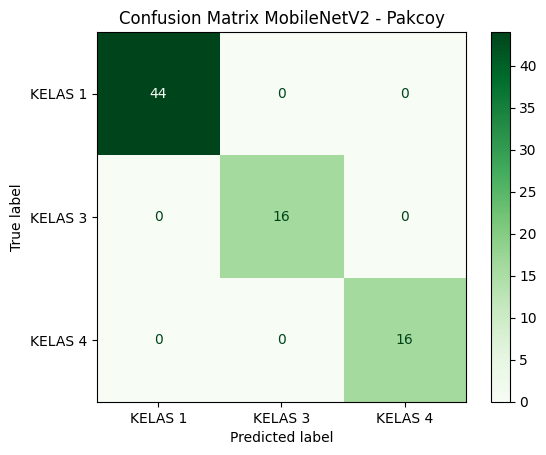

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_ds.class_names
)

disp.plot(
    cmap="Greens",
    values_format="d"
)

plt.title(
    "Confusion Matrix MobileNetV2 - Pakcoy"
)

plt.show()

In [ ]:
MODEL_PATH = "/content/pakcoy_demo_3kelas.keras"

model.save(MODEL_PATH)

print("Model tersimpan:")
print(MODEL_PATH)

Model tersimpan:
/content/pakcoy_demo_3kelas.keras


In [ ]:
import json

class_names = train_ds.class_names

with open(
    "/content/class_names_demo.json",
    "w"
) as f:

    json.dump(
        class_names,
        f,
        indent=4
    )

print("Class names:", class_names)

Class names: ['KELAS 1', 'KELAS 3', 'KELAS 4']


In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(
    model
)

tflite_model = converter.convert()

with open(
    "/content/pakcoy_demo_3kelas.tflite",
    "wb"
) as f:

    f.write(tflite_model)

print("TFLite berhasil dibuat.")

Saved artifact at '/tmp/tmp149uo9qg'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  134939976536080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134939976536272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134939976538384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134939976538576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134939976537424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134939976537808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134939976538000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134939976539344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134939976538192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134939976537616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1349399765

In [ ]:
from google.colab import files

files.download(
    "/content/pakcoy_demo_3kelas.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download(
    "/content/pakcoy_demo_3kelas.tflite"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download(
    "/content/class_names_demo.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

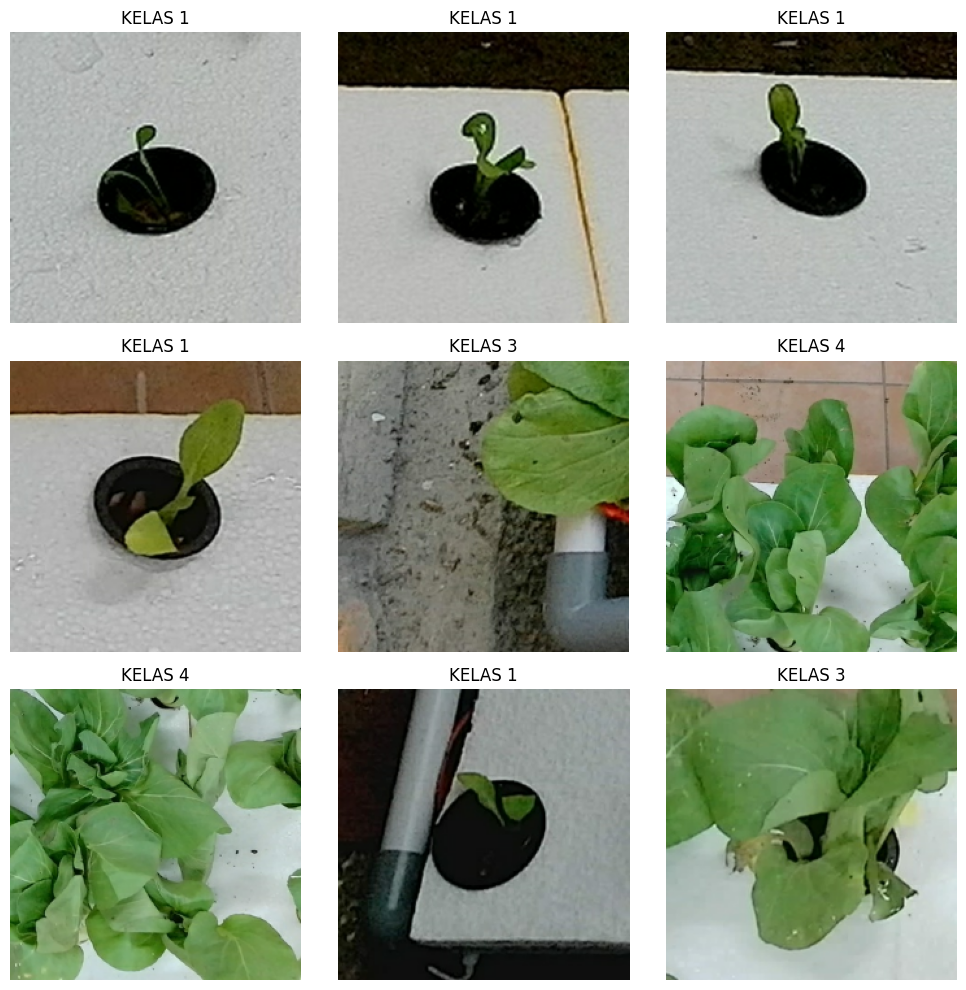

In [ ]:
import matplotlib.pyplot as plt

class_names = train_ds.class_names

plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(
            images[i].numpy().astype("uint8")
        )

        plt.title(
            class_names[labels[i]]
        )

        plt.axis("off")

plt.tight_layout()
plt.show()

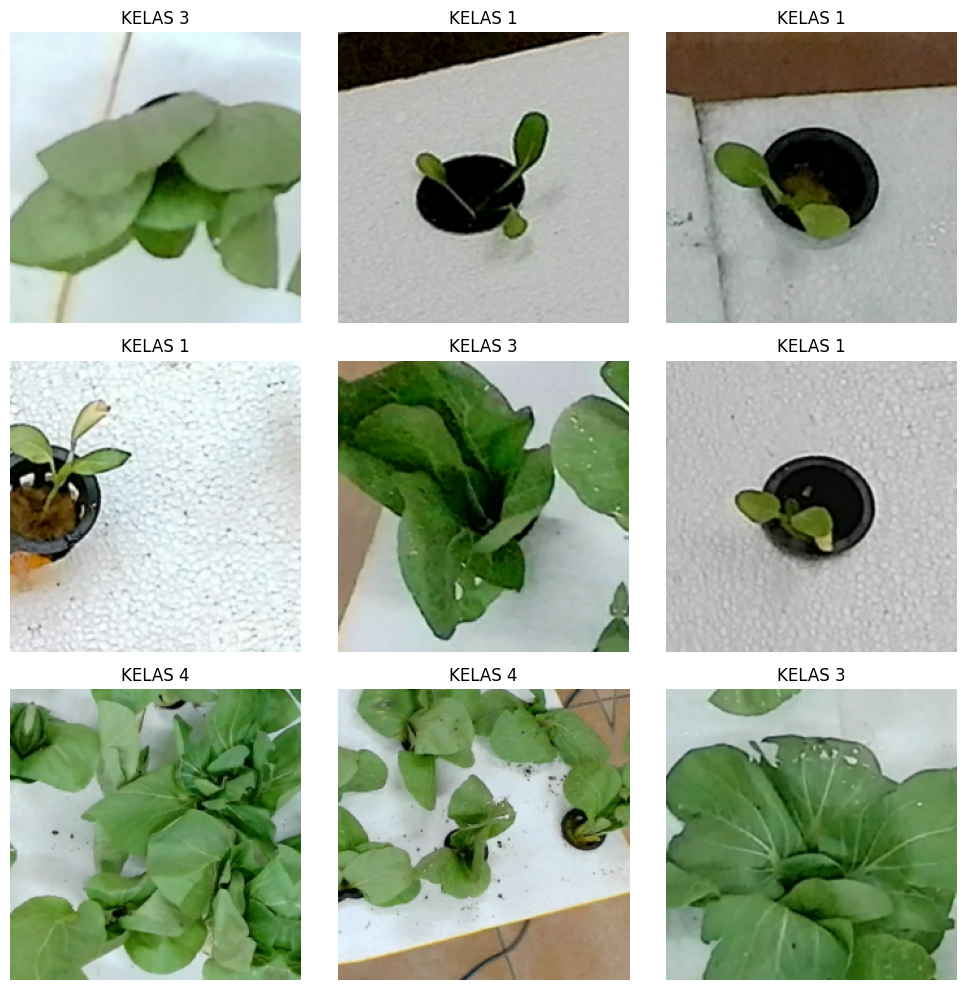

In [ ]:
import matplotlib.pyplot as plt

for images, labels in train_ds.take(1):

    plt.figure(figsize=(10, 10))

    for i in range(9):

        augmented = data_augmentation(
            images[i:i+1],
            training=True
        )

        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(
            augmented[0]
            .numpy()
            .astype("uint8")
        )

        plt.title(
            class_names[labels[i]]
        )

        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print("\nHASIL EVALUASI")
print("====================")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Accuracy (%)  : {test_accuracy * 100:.2f}%")

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 1.0000 - loss: 0.0020

HASIL EVALUASI
Test Loss     : 0.0020
Test Accuracy : 1.0000
Accuracy (%)  : 100.00%


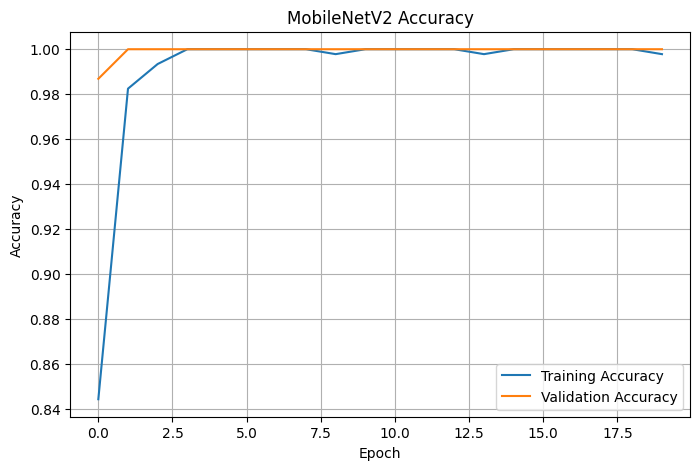

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 Accuracy")
plt.legend()
plt.grid()

plt.show()

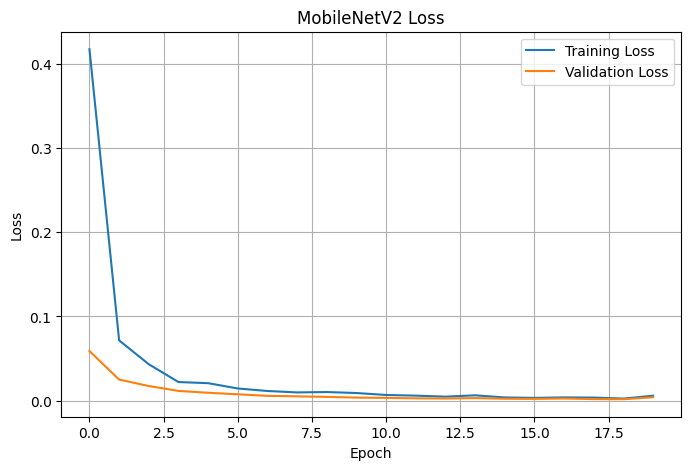

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV2 Loss")
plt.legend()
plt.grid()

plt.show()

In [ ]:
import numpy as np

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = model.predict(
        images,
        verbose=0
    )

    predictions = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(labels.numpy())
    y_pred.extend(predictions)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=train_ds.class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

     KELAS 1     1.0000    1.0000    1.0000        44
     KELAS 3     1.0000    1.0000    1.0000        16
     KELAS 4     1.0000    1.0000    1.0000        16

    accuracy                         1.0000        76
   macro avg     1.0000    1.0000    1.0000        76
weighted avg     1.0000    1.0000    1.0000        76



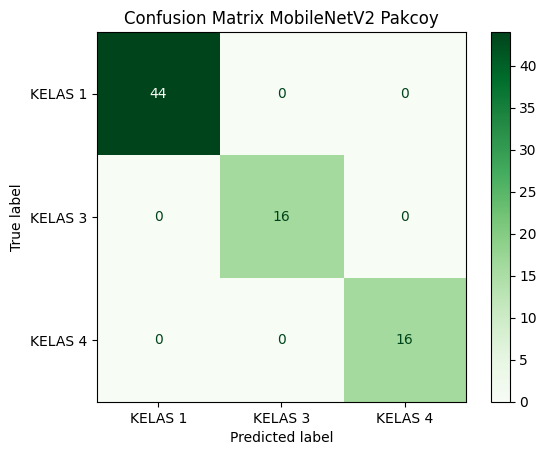

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_ds.class_names
)

disp.plot(
    cmap="Greens",
    values_format="d"
)

plt.title(
    "Confusion Matrix MobileNetV2 Pakcoy"
)

plt.show()

In [ ]:
model.save(
    "/content/pakcoy_demo_3kelas.keras"
)

print("Model berhasil disimpan.")

Model berhasil disimpan.


In [ ]:
import json

with open(
    "/content/class_names_demo.json",
    "w"
) as f:

    json.dump(
        train_ds.class_names,
        f,
        indent=4
    )

print(train_ds.class_names)

['KELAS 1', 'KELAS 3', 'KELAS 4']


In [ ]:
from google.colab import files

files.download(
    "/content/pakcoy_demo_3kelas.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download(
    "/content/class_names_demo.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>